# FloodCastBench: download and explore the data

DL Lab project by Anhad Mahajan and Aman Sumeet Saxena

This notebook downloads the whole dataset, checks that it is complete and looks at every flood.
There is no model training here, and nothing is saved to Google Drive.

Parts of this notebook:

1. Download the data
2. What is in the dataset
3. The four regions
4. How each flood changes
5. Rain and flood over time
6. Which rain map goes with which depth map
7. Is the old "severe" label measuring the flood?
8. Summary

## 0. Setup

In [13]:
# Install rasterio, the library that reads map files (.tif)
!pip install -q rasterio

In [14]:
# Basic libraries
import os
import glob
import time
import shutil

# Numbers, tables and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Map files and the dataset download
import rasterio
from huggingface_hub import snapshot_download, HfApi

### Settings

In [15]:
# Name of the dataset on Hugging Face
REPO_ID = "mahajananhad/floodcastbench"

# Folder on Colab where the dataset is saved (it is wiped when the session ends)
DATA_DIR = "/content/floodcastbench"

# The four flood regions
REGIONS = ["Australia", "UK", "Pakistan", "Mozambique"]

# Folder holding the water-depth maps of each region at each map scale
DEPTH_FOLDERS = {
    "Australia 30m": "High-fidelity flood forecasting/30m/Australia",
    "UK 30m": "High-fidelity flood forecasting/30m/UK",
    "Australia 60m": "High-fidelity flood forecasting/60m/Australia",
    "UK 60m": "High-fidelity flood forecasting/60m/UK",
    "Pakistan 480m": "Low-fidelity flood forecasting/480m/Pakistan",
    "Mozambique 480m": "Low-fidelity flood forecasting/480m/Mozambique",
}

# Which region each dataset belongs to
REGION_OF = {
    "Australia 30m": "Australia",
    "UK 30m": "UK",
    "Australia 60m": "Australia",
    "UK 60m": "UK",
    "Pakistan 480m": "Pakistan",
    "Mozambique 480m": "Mozambique",
}

# Water depth at the moment each simulation starts
START_WATER_FILES = {
    "Australia": "Relevant data/Initial conditions/High-fidelity flood forecasting/Australia_30m.tif",
    "UK": "Relevant data/Initial conditions/High-fidelity flood forecasting/UK_30m.tif",
    "Pakistan": "Relevant data/Initial conditions/Low-fidelity flood forecasting/Pakistan_480m.tif",
    "Mozambique": "Relevant data/Initial conditions/Low-fidelity flood forecasting/Mozambique_480m.tif",
}

# Time between two depth maps: 300 seconds = 5 minutes
DEPTH_STEP_SECONDS = 300

# Time between two rain maps: 1800 seconds = 30 minutes
RAIN_STEP_SECONDS = 1800

# One rain map covers the same time as 6 depth maps
DEPTH_MAPS_PER_RAIN_MAP = 6

# Water above 1 cm counts as wet
WET_DEPTH_M = 0.01

## 1. Download the data

The whole dataset is about 27 GB, so the download takes a while.

In [16]:
# Check that Colab has enough free disk space
total, used, free = shutil.disk_usage("/content")

print("Free disk space:", round(free / 1e9, 1), "GB")
print("Space needed:    about 30 GB")

Free disk space: 62.9 GB
Space needed:    about 30 GB


In [17]:
# Load the Hugging Face token from Colab's secrets (key icon on the left), if there is one
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
    print("Token found")
except Exception:
    HF_TOKEN = None
    print("No token found, downloading without one")

Token found


In [18]:
start_time = time.time()

# Try up to 5 times, because large downloads sometimes stop halfway
for attempt in range(1, 6):
    try:
        # Files that are already downloaded are skipped, so a retry carries on where it stopped
        snapshot_download(repo_id=REPO_ID, repo_type="dataset", local_dir=DATA_DIR,
                          token=HF_TOKEN, max_workers=8)
        print("Download complete")
        break
    except Exception as error:
        print("Attempt", attempt, "failed:", error)
        print("Waiting 60 seconds before trying again")
        time.sleep(60)

print("Time taken:", round((time.time() - start_time) / 60, 1), "minutes")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14870 files:   0%|          | 0/14870 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/mahajananhad/floodcastbench/15a894f18e55580e7de84796d01e5eeec8b95395/Low-fidelity%20flood%20forecasting%2F480m%2FMozambique%2F89100.tif?%2Fdatasets%2Fmahajananhad%2Ffloodcastbench%2Fresolve%2F15a894f18e55580e7de84796d01e5eeec8b95395%2FLow-fidelity+flood+forecasting%2F480m%2FMozambique%2F89100.tif=&etag=%22bff1cda9cafe162a5020f0e9525b912f3cdda1b4%22
Rate limited. Waiting 113.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/mahajananhad/floodcastbench/resolve/15a894f18e55580e7de84796d01e5eeec8b95395/Low-fidelity%20flood%20forecasting/480m/Mozambique/89400.tif
Rate limited. Waiting 113.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/mahajananhad/floodcastbench/resolve/15a894f18e55580e7de84796d01e5eeec8b95395/Low-fidelity%20flood%20forecasting/480m/Mozambique/88800.tif
Rate limited. Wait

Download complete
Time taken: 60.0 minutes


In [19]:
# List of every file in the dataset on Hugging Face
api = HfApi()
all_files = api.list_repo_files(REPO_ID, repo_type="dataset", token=HF_TOKEN)

# Find any file that did not arrive on Colab
missing_files = []
for file_name in all_files:
    if not os.path.exists(os.path.join(DATA_DIR, file_name)):
        missing_files.append(file_name)

print("Files in the dataset:", len(all_files))
print("Files missing:       ", len(missing_files))

if len(missing_files) > 0:
    print("Missing examples:", missing_files[:5])
    print("Run the download cell again to fetch them")

Files in the dataset: 14870
Files missing:        0


### Small helper functions

In [20]:
def get_seconds(file_path):
    # Turn a depth file name like "300.tif" into the number 300
    file_name = os.path.basename(file_path)
    return int(file_name.replace(".tif", ""))


def get_depth_files(dataset):
    # The depth maps of one dataset, in time order
    folder = os.path.join(DATA_DIR, DEPTH_FOLDERS[dataset])
    files = glob.glob(os.path.join(folder, "*.tif"))

    # Each file is named after its time in seconds, so sort by that number
    files.sort(key=get_seconds)
    return files


def get_rain_files(region):
    # The rain maps of one region, in time order
    folder = os.path.join(DATA_DIR, "Relevant data", "Rainfall", region + " flood")
    files = glob.glob(os.path.join(folder, "*.tif"))

    # Rain files are named by date and time (e.g. 20151204-S120000.tif), so alphabetical order is time order
    files.sort()
    return files


def read_map(file_path, max_size=None):
    # Read one map file into a 2D array. With max_size, big maps are shrunk so they load and plot faster
    with rasterio.open(file_path) as source:
        if max_size is None:
            data = source.read(1)
        else:
            # Shrink the map so its longest side is about max_size
            longest_side = max(source.height, source.width)
            shrink = max(1, int(np.ceil(longest_side / max_size)))
            data = source.read(1, out_shape=(source.height // shrink, source.width // shrink))

    data = data.astype("float32")

    # These files mark "no data" with a huge negative number, so turn those into NaN
    data[data < -1e30] = np.nan
    return data

## 2. What is in the dataset

One row for each set of depth maps and each set of rain maps.

In [21]:
# Depth maps: how many, how many hours, how big, and are they evenly spaced?
depth_rows = []

for dataset in DEPTH_FOLDERS:
    files = get_depth_files(dataset)
    seconds = [get_seconds(f) for f in files]

    # Every gap between two maps should be exactly 5 minutes
    evenly_spaced = bool(np.all(np.diff(seconds) == DEPTH_STEP_SECONDS))

    with rasterio.open(files[0]) as source:
        map_size = str(source.height) + " x " + str(source.width)

    depth_rows.append({
        "Dataset": dataset,
        "Number of depth maps": len(files),
        "Hours covered": (seconds[-1] - seconds[0]) / 3600,
        "Map size (rows x columns)": map_size,
        "Every 5 minutes?": evenly_spaced,
    })

print("DEPTH MAPS")
display(pd.DataFrame(depth_rows))

# Rain maps of each region
rain_rows = []

for region in REGIONS:
    files = get_rain_files(region)

    with rasterio.open(files[0]) as source:
        map_size = str(source.height) + " x " + str(source.width)

    rain_rows.append({
        "Region": region,
        "Number of rain maps": len(files),
        "Hours covered": (len(files) - 1) * RAIN_STEP_SECONDS / 3600,
        "Map size (rows x columns)": map_size,
    })

print("RAIN MAPS")
display(pd.DataFrame(rain_rows))

DEPTH MAPS


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


,Dataset,Number of depth maps,Hours covered,Map size (rows x columns),Every 5 minutes?
0,Australia 30m,2881,240.0,1073 x 1073,True
1,UK 30m,865,72.0,170 x 275,True
2,Australia 60m,2881,240.0,536 x 536,True
3,UK 60m,865,72.0,85 x 137,True
4,Pakistan 480m,4033,336.0,810 x 441,True
5,Mozambique 480m,1729,144.0,151 x 138,True


RAIN MAPS


,Region,Number of rain maps,Hours covered,Map size (rows x columns)
0,Australia,481,240.0,1073 x 1073
1,UK,145,72.0,180 x 285
2,Pakistan,672,335.5,13035 x 7298
3,Mozambique,289,144.0,2624 x 2321


## 3. The four regions

For each region: how high the ground is, what covers the ground, and the water already there when the simulation starts.

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


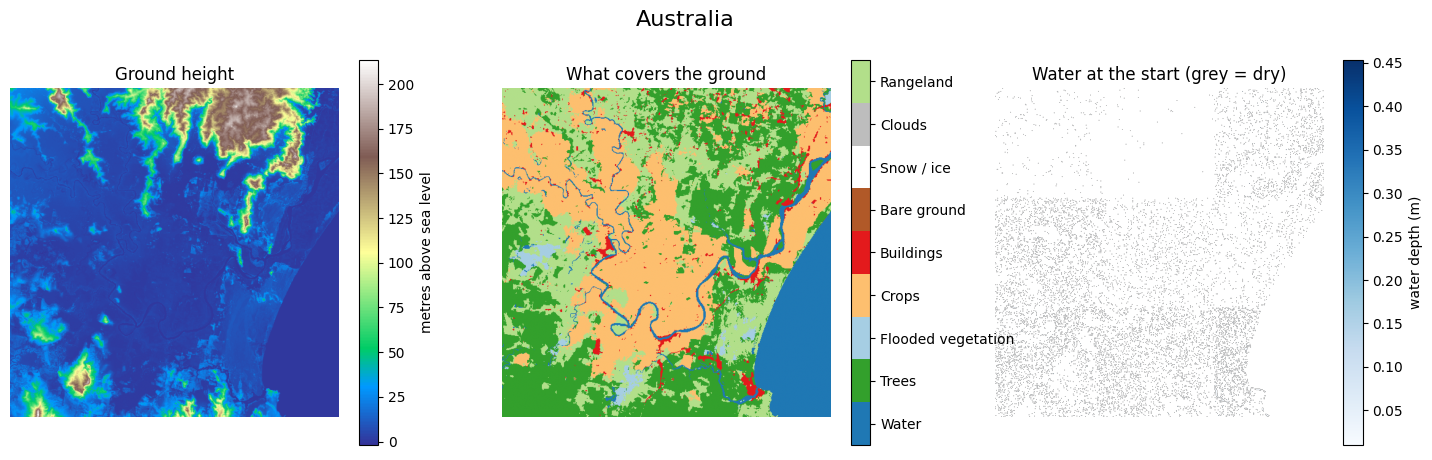

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


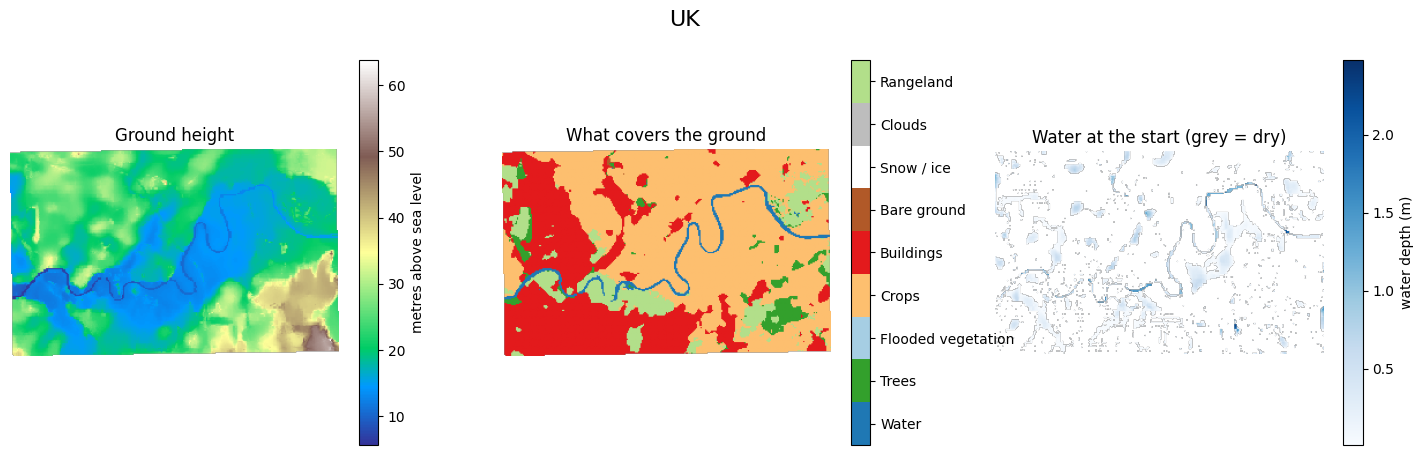

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


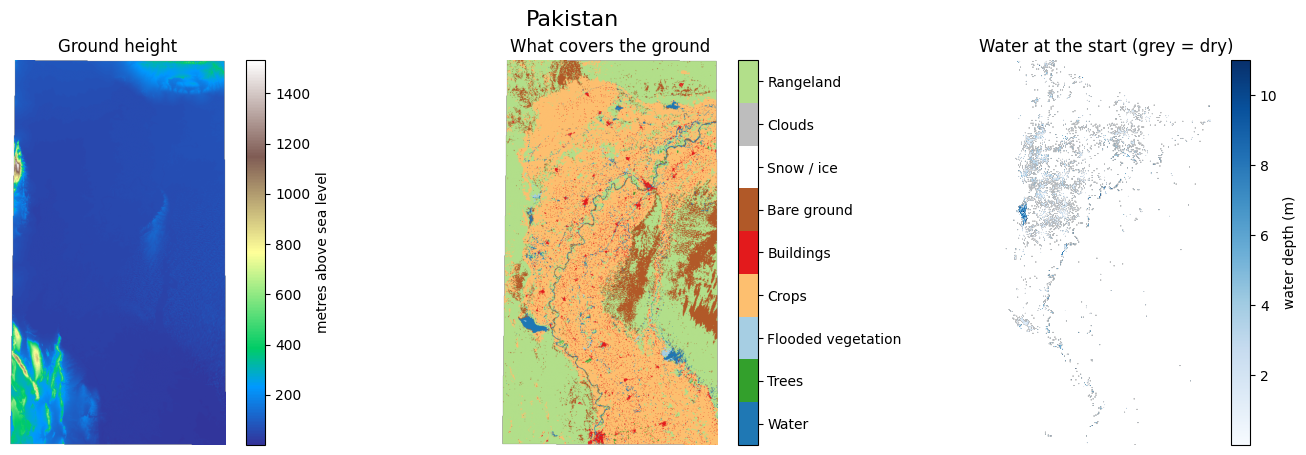

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


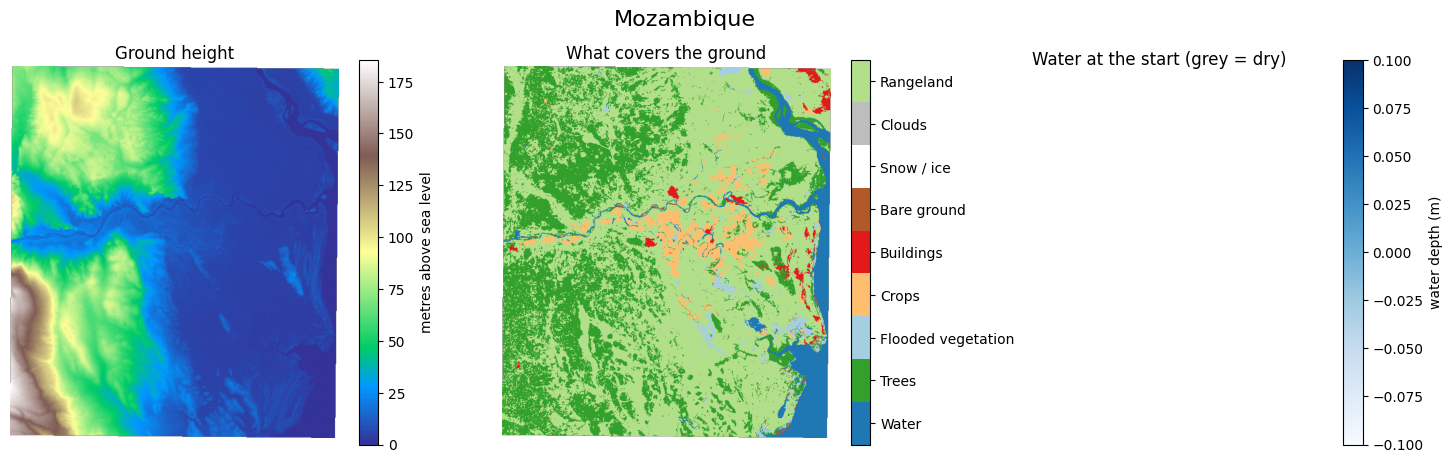

In [22]:
# Name and colour of each land-cover code
LAND_USE = {
    1: ("Water", "#1f78b4"),
    2: ("Trees", "#33a02c"),
    4: ("Flooded vegetation", "#a6cee3"),
    5: ("Crops", "#fdbf6f"),
    7: ("Buildings", "#e31a1c"),
    8: ("Bare ground", "#b15928"),
    9: ("Snow / ice", "#ffffff"),
    10: ("Clouds", "#bdbdbd"),
    11: ("Rangeland", "#b2df8a"),
}

land_use_codes = list(LAND_USE.keys())
land_use_names = [LAND_USE[code][0] for code in land_use_codes]
land_use_colours = ListedColormap([LAND_USE[code][1] for code in land_use_codes])

for region in REGIONS:
    dem_path = os.path.join(DATA_DIR, "Relevant data", "DEM", region + "_DEM.tif")
    land_use_path = os.path.join(DATA_DIR, "Relevant data", "Land use and land cover", region + ".tif")
    start_water_path = os.path.join(DATA_DIR, START_WATER_FILES[region])

    ground_height = read_map(dem_path, max_size=800)
    land_use = read_map(land_use_path, max_size=800)
    start_water = read_map(start_water_path, max_size=800)

    # Turn each land-cover code into a position 0, 1, 2, ... so each gets its own colour
    land_use_position = np.full(land_use.shape, np.nan)
    for position, code in enumerate(land_use_codes):
        land_use_position[land_use == code] = position

    # Hide squares with less than 1 cm of water, so the water stands out
    start_water[start_water < WET_DEPTH_M] = np.nan

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(region, fontsize=16)

    # Left: how high the ground is
    picture = axes[0].imshow(ground_height, cmap="terrain")
    axes[0].set_title("Ground height")
    fig.colorbar(picture, ax=axes[0], label="metres above sea level")

    # Middle: what covers the ground
    picture = axes[1].imshow(land_use_position, cmap=land_use_colours, vmin=-0.5, vmax=len(land_use_codes) - 0.5)
    axes[1].set_title("What covers the ground")
    colour_bar = fig.colorbar(picture, ax=axes[1], ticks=range(len(land_use_codes)))
    colour_bar.ax.set_yticklabels(land_use_names)

    # Right: water already on the ground when the simulation starts
    axes[2].set_facecolor("lightgrey")
    picture = axes[2].imshow(start_water, cmap="Blues")
    axes[2].set_title("Water at the start (grey = dry)")
    fig.colorbar(picture, ax=axes[2], label="water depth (m)")

    for ax in axes:
        ax.axis("off")

    plt.show()

## 4. How each flood changes

Six moments spread from the start to the end of each flood, on the same colour scale.

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


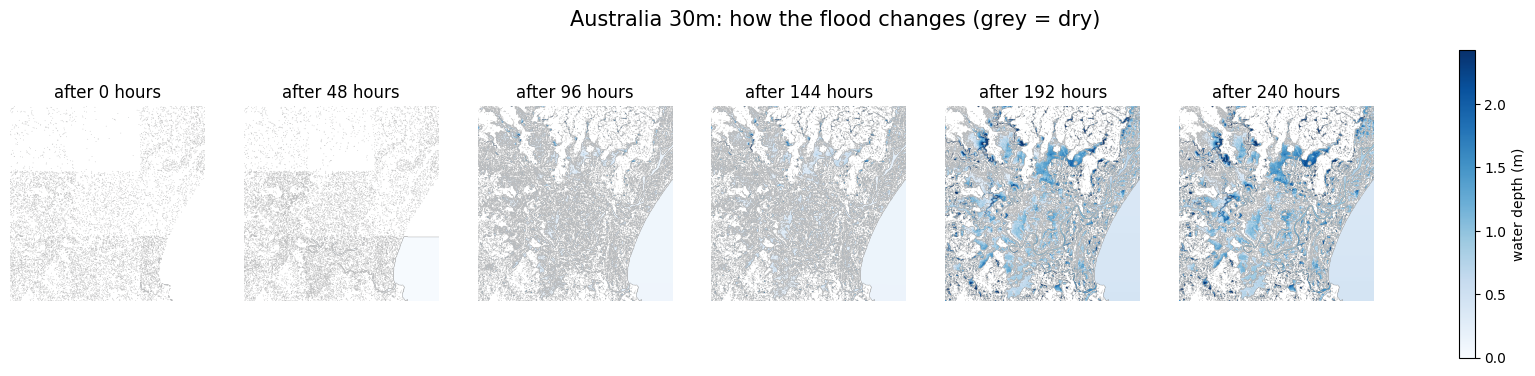

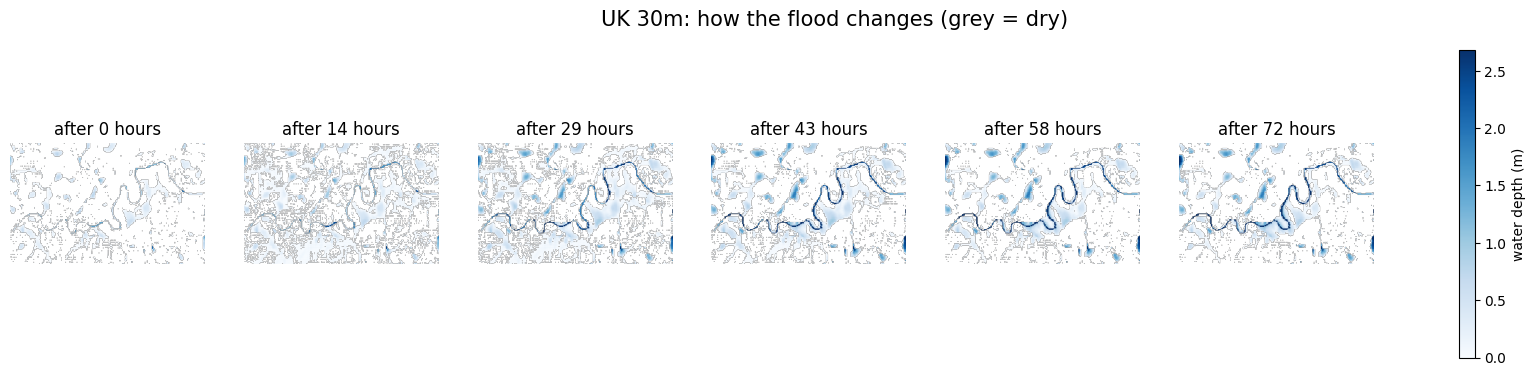

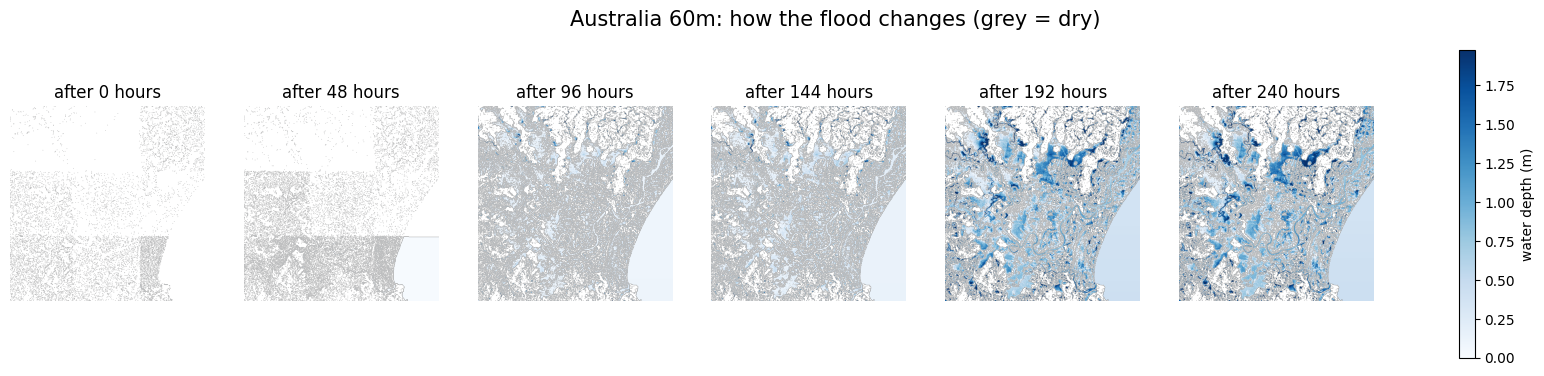

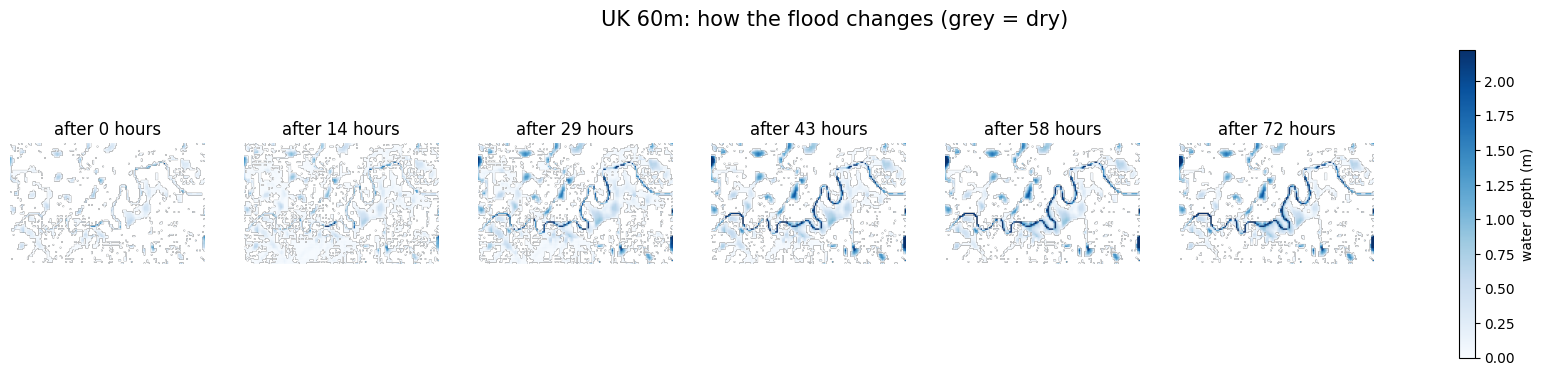

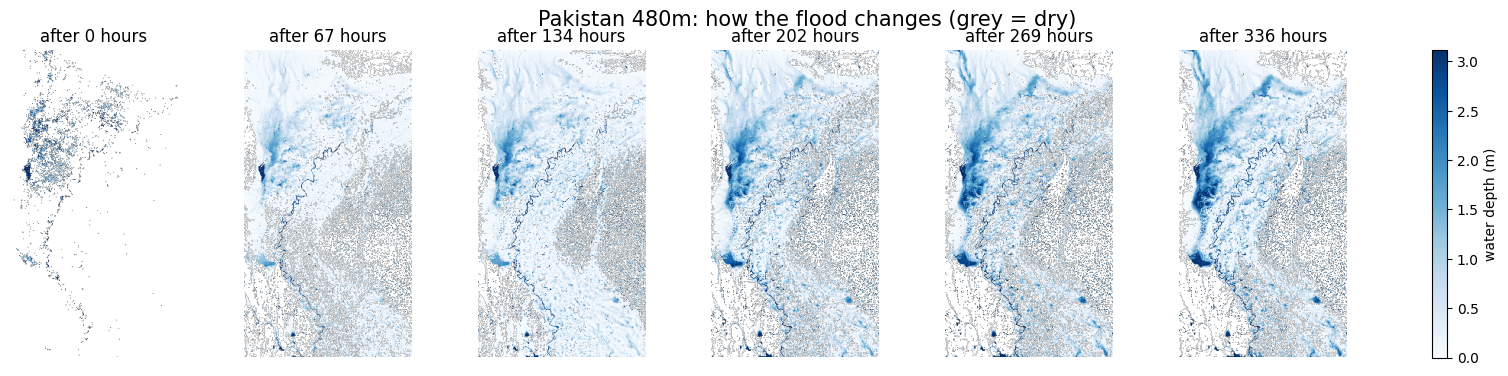

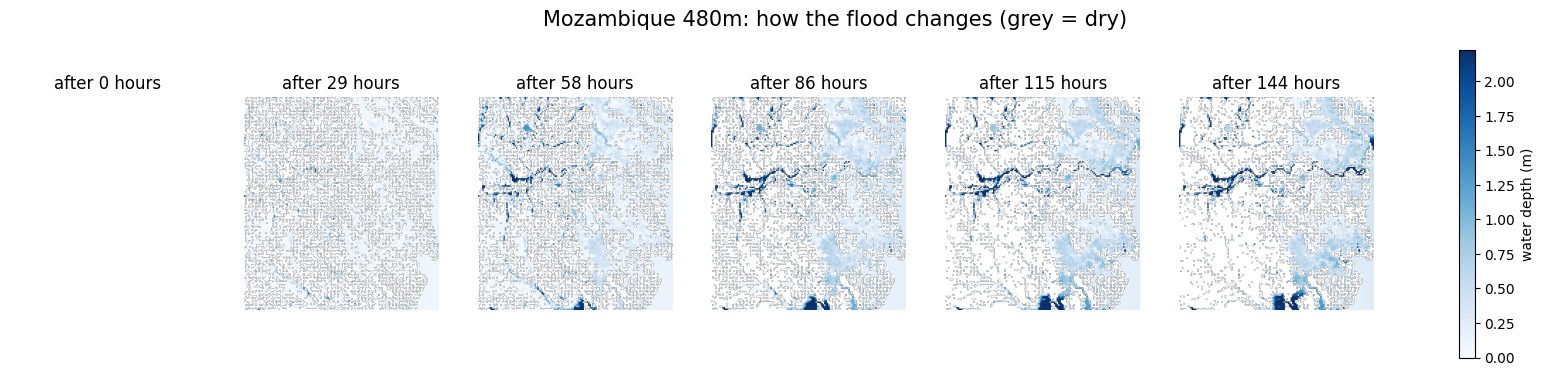

In [23]:
for dataset in DEPTH_FOLDERS:
    files = get_depth_files(dataset)

    # 6 moments spread evenly over the flood
    picked = np.linspace(0, len(files) - 1, 6).astype(int)

    maps = []
    for number in picked:
        maps.append(read_map(files[number], max_size=800))

    # Same colour scale for all 6 pictures, so they can be compared
    all_wet_values = np.concatenate([m[m > WET_DEPTH_M] for m in maps])
    deepest_shown = np.percentile(all_wet_values, 98)

    fig, axes = plt.subplots(1, 6, figsize=(22, 4))
    fig.suptitle(dataset + ": how the flood changes (grey = dry)", fontsize=15)

    for ax, depth, number in zip(axes, maps, picked):
        # Hide squares with less than 1 cm of water
        depth[depth < WET_DEPTH_M] = np.nan

        ax.set_facecolor("lightgrey")
        picture = ax.imshow(depth, cmap="Blues", vmin=0, vmax=deepest_shown)

        hours = get_seconds(files[number]) / 3600
        ax.set_title("after " + str(round(hours)) + " hours")
        ax.axis("off")

    fig.colorbar(picture, ax=axes, label="water depth (m)")
    plt.show()

## 5. Rain and flood over time

Every 30 minutes we measure the average depth, the deepest point, the wet area and the average rain.
We also count impossible values (missing or negative depths).

In [24]:
# Rain and water measurements every 30 minutes, for every dataset
measurements = {}

for dataset in DEPTH_FOLDERS:
    region = REGION_OF[dataset]

    # One depth map every 30 minutes, the same spacing as the rain maps
    depth_files = get_depth_files(dataset)[::DEPTH_MAPS_PER_RAIN_MAP]
    rain_files = get_rain_files(region)

    average_depth = []
    deepest_point = []
    wet_area = []
    average_rain = []
    impossible_values = 0

    for step, depth_file in enumerate(depth_files):
        depth = read_map(depth_file)

        # Values that should never exist: missing values or negative depth
        impossible_values += int(np.isnan(depth).sum())
        impossible_values += int((depth < 0).sum())

        average_depth.append(np.nanmean(depth))
        deepest_point.append(np.nanmax(depth))

        # Share of the map with more than 1 cm of water
        wet_area.append(np.nanmean(depth > WET_DEPTH_M))

        # Average rain in the rain map with the same step number
        if step < len(rain_files):
            rain = read_map(rain_files[step], max_size=400)
            average_rain.append(np.nanmean(rain))
        else:
            average_rain.append(np.nan)

    measurements[dataset] = {
        "hours": np.arange(len(depth_files)) * 0.5,
        "average_depth": np.array(average_depth),
        "deepest_point": np.array(deepest_point),
        "wet_area": np.array(wet_area),
        "average_rain": np.array(average_rain),
    }

    print(dataset, "- maps checked:", len(depth_files), "- impossible values found:", impossible_values)

Australia 30m - maps checked: 481 - impossible values found: 0
UK 30m - maps checked: 145 - impossible values found: 0
Australia 60m - maps checked: 481 - impossible values found: 0
UK 60m - maps checked: 145 - impossible values found: 0
Pakistan 480m - maps checked: 673 - impossible values found: 0
Mozambique 480m - maps checked: 289 - impossible values found: 0


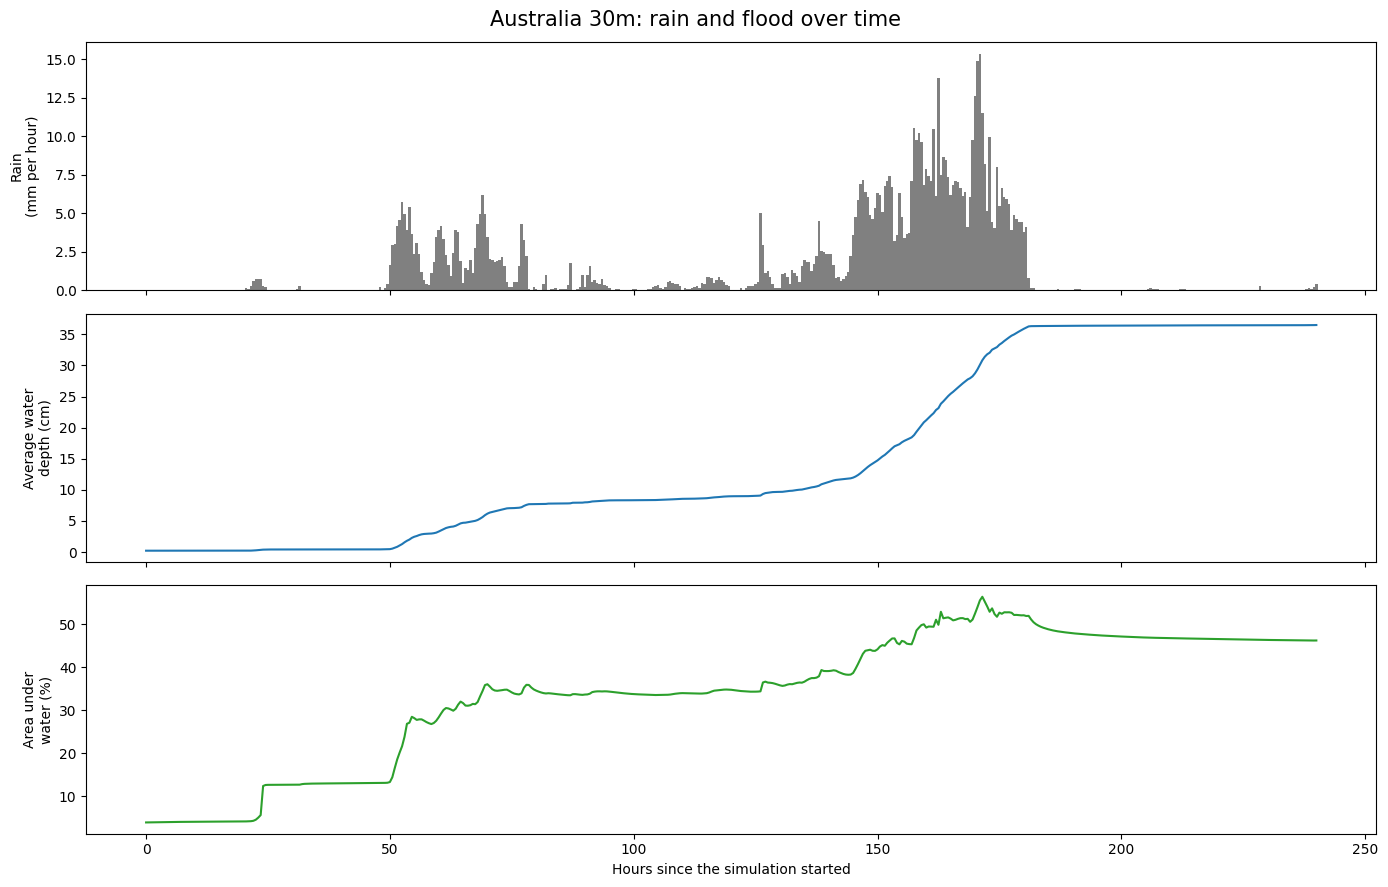

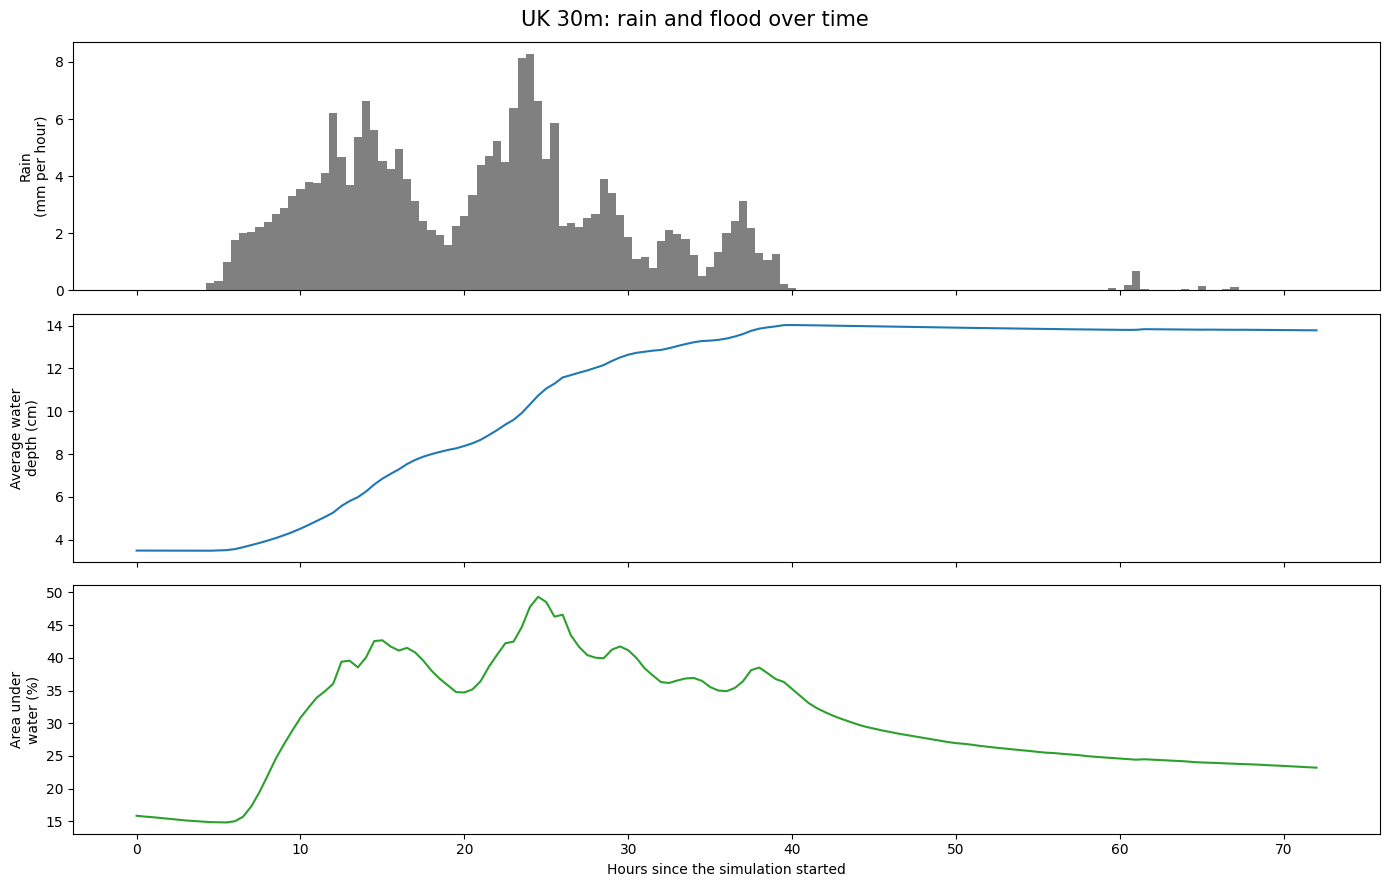

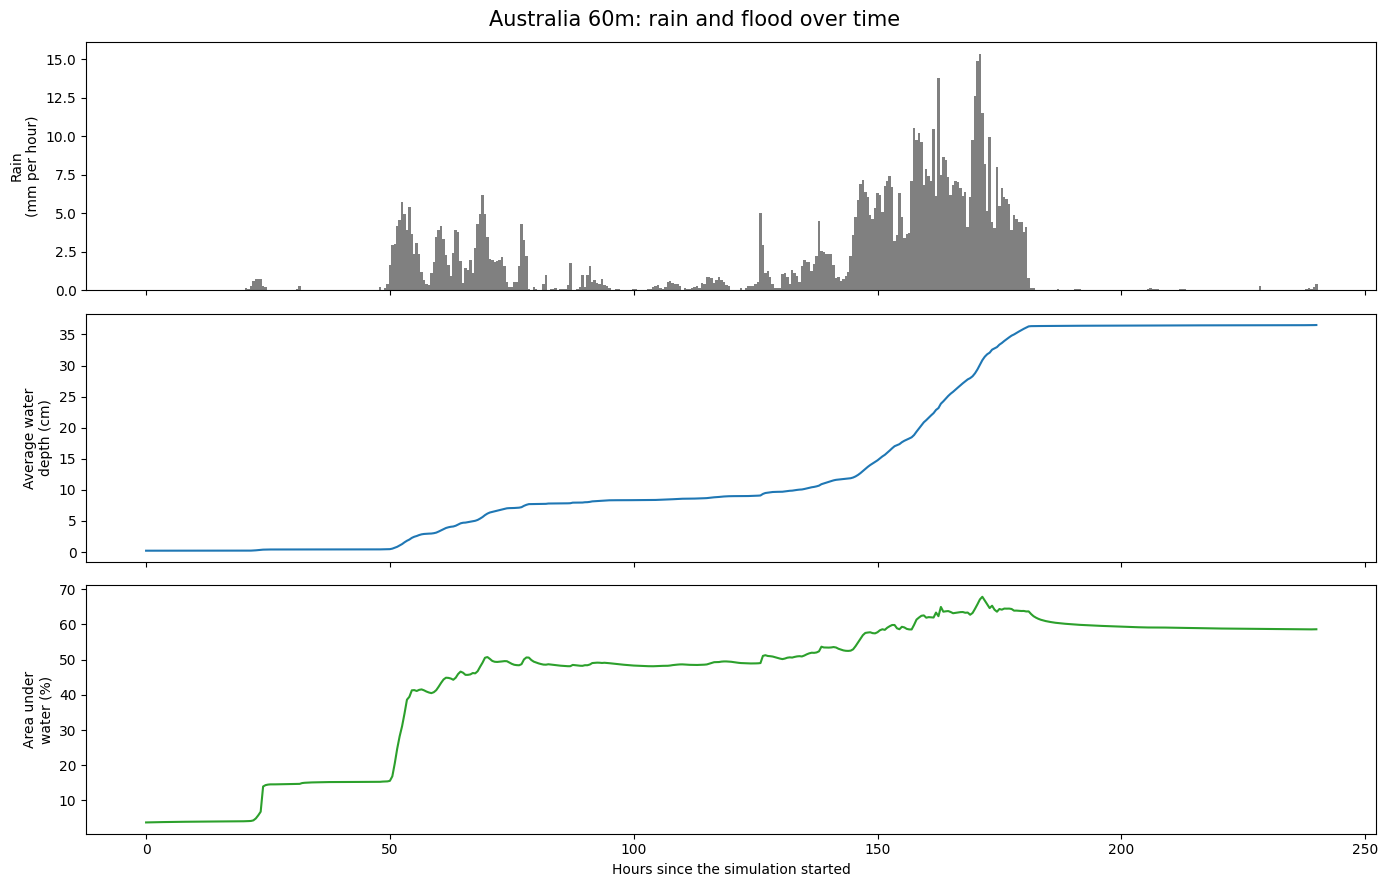

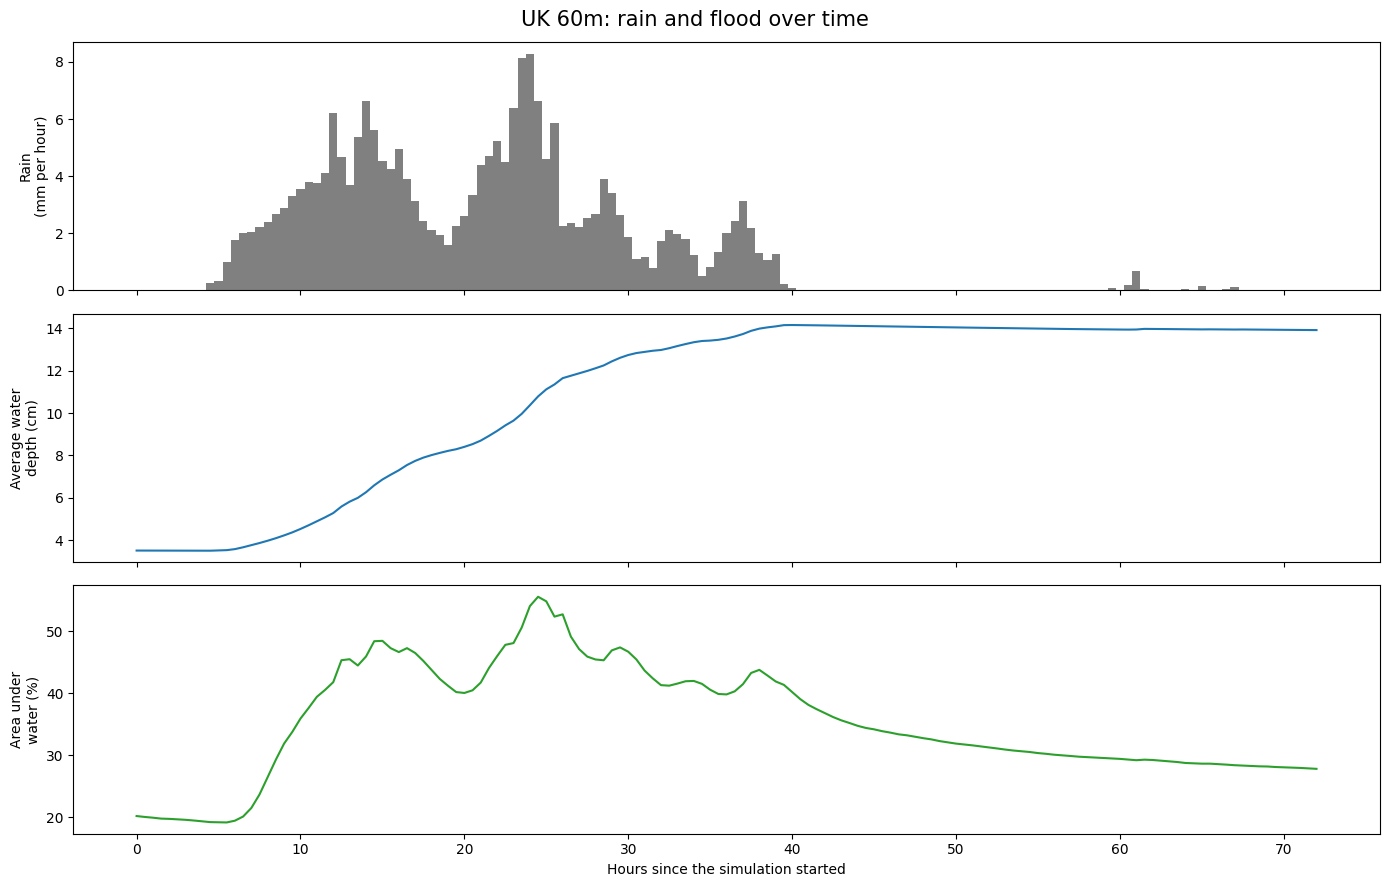

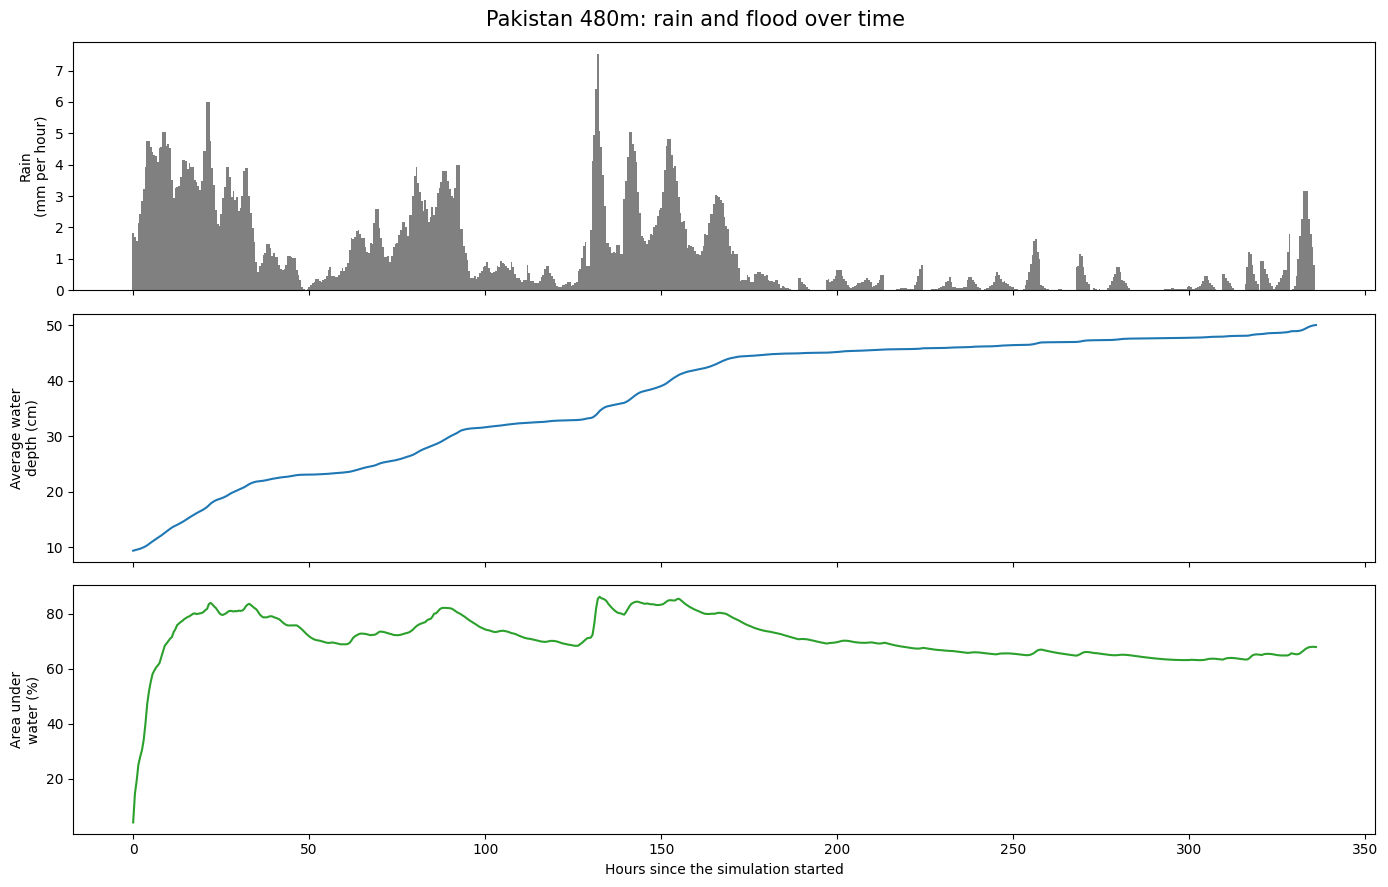

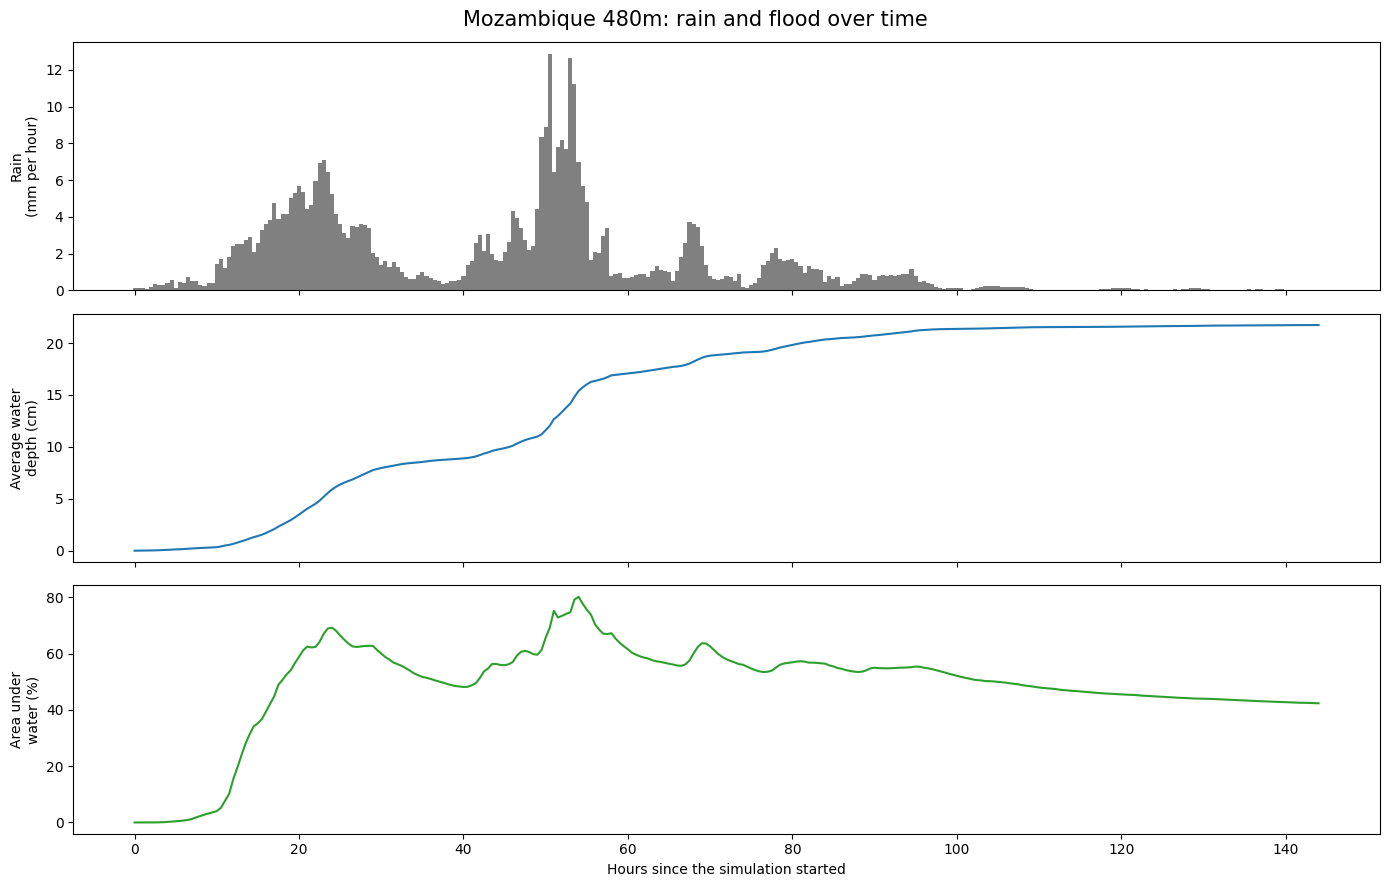

In [25]:
for dataset, m in measurements.items():
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
    fig.suptitle(dataset + ": rain and flood over time", fontsize=15)

    # Top: how hard it rained
    axes[0].bar(m["hours"], m["average_rain"], width=0.5, color="grey")
    axes[0].set_ylabel("Rain\n(mm per hour)")

    # Middle: average water depth over the whole map
    axes[1].plot(m["hours"], m["average_depth"] * 100, color="tab:blue")
    axes[1].set_ylabel("Average water\ndepth (cm)")

    # Bottom: how much of the map is under water
    axes[2].plot(m["hours"], m["wet_area"] * 100, color="tab:green")
    axes[2].set_ylabel("Area under\nwater (%)")
    axes[2].set_xlabel("Hours since the simulation started")

    plt.tight_layout()
    plt.show()

## 6. Which rain map goes with which depth map

The water added in each half hour should follow the rain that fell in that half hour.
We compare it with the rain map stamped 30 minutes earlier, at the same time, and 30 minutes later.
If all the rain stayed on the ground, the water added would be 0.5 x the hourly rain rate.

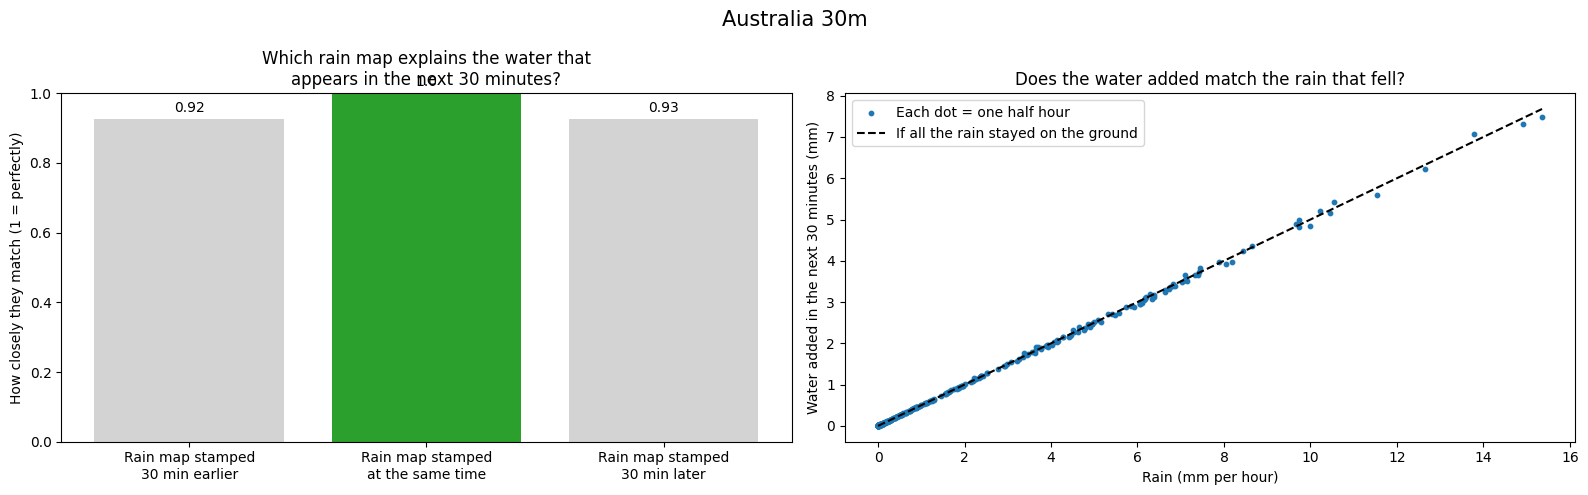

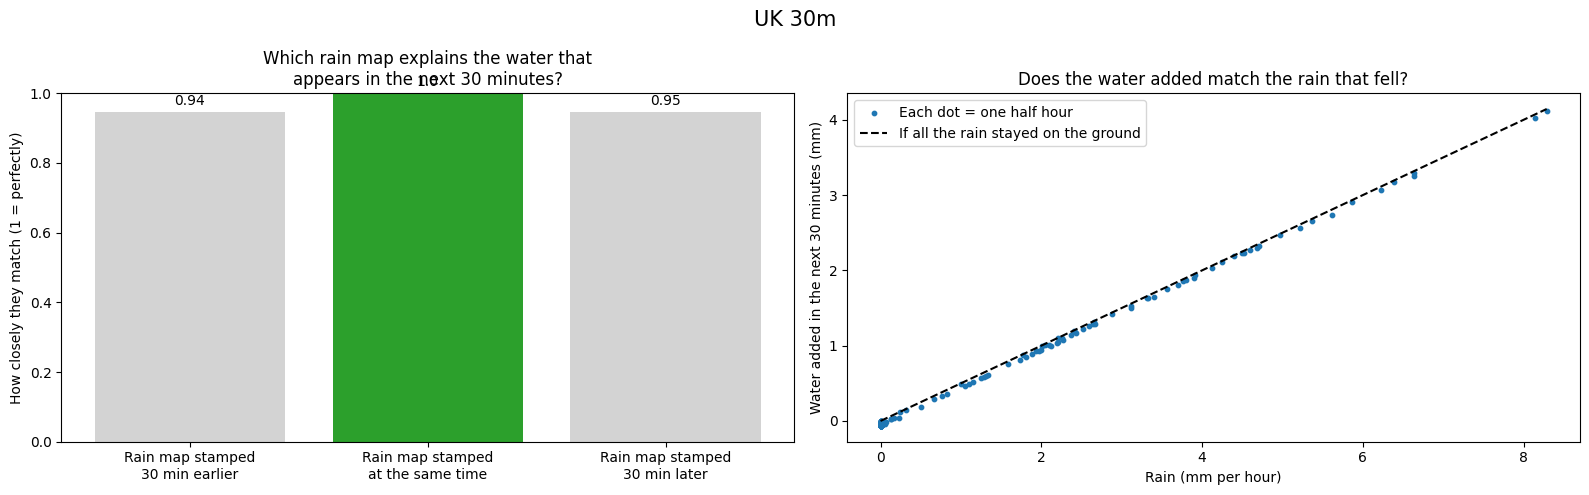

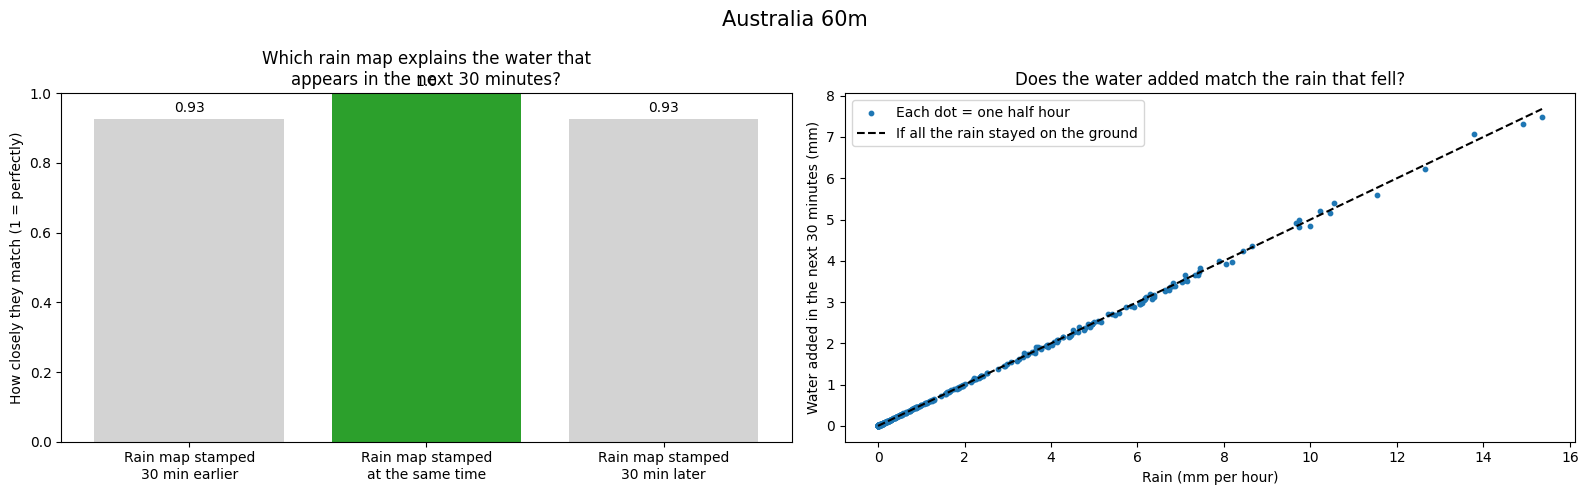

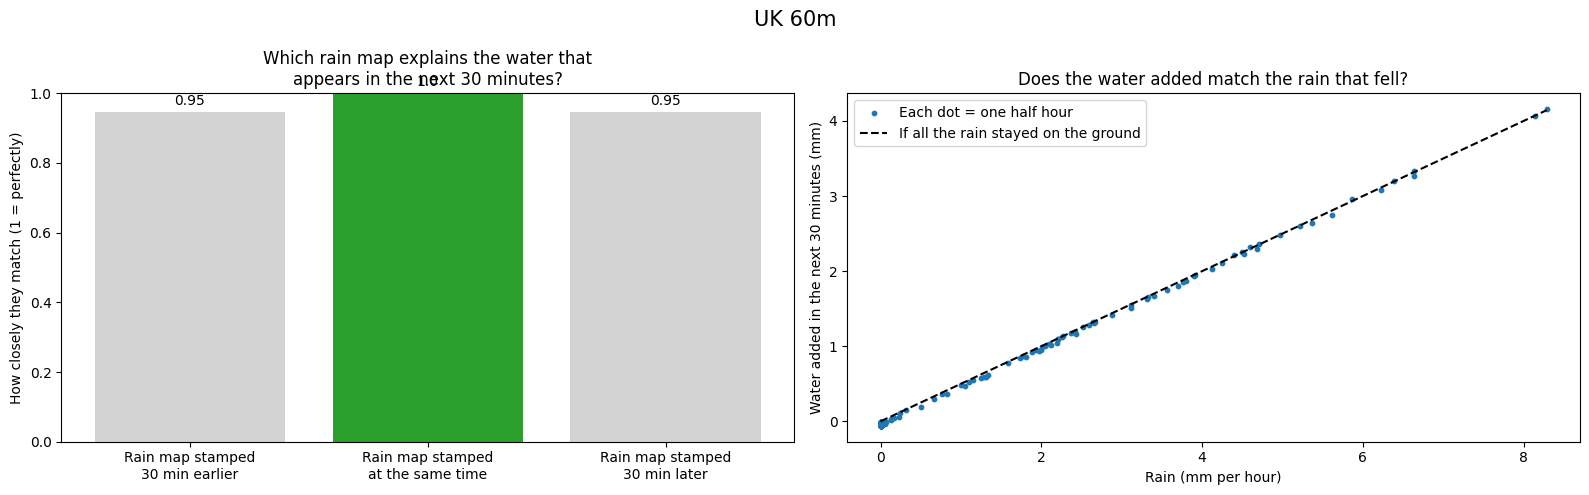

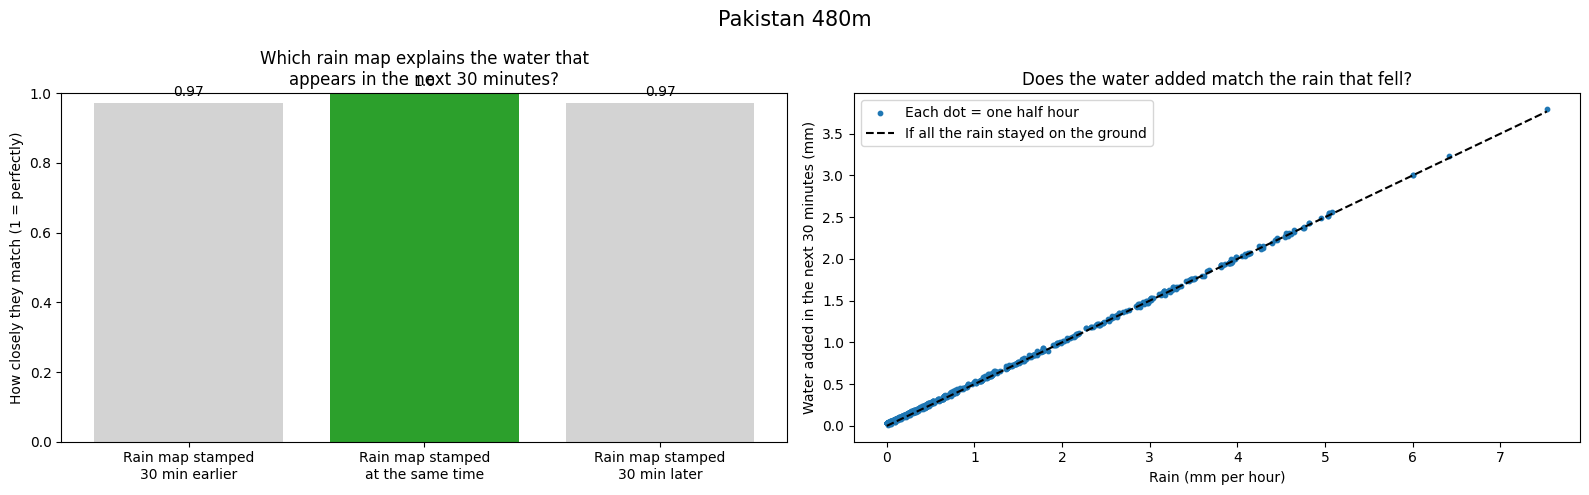

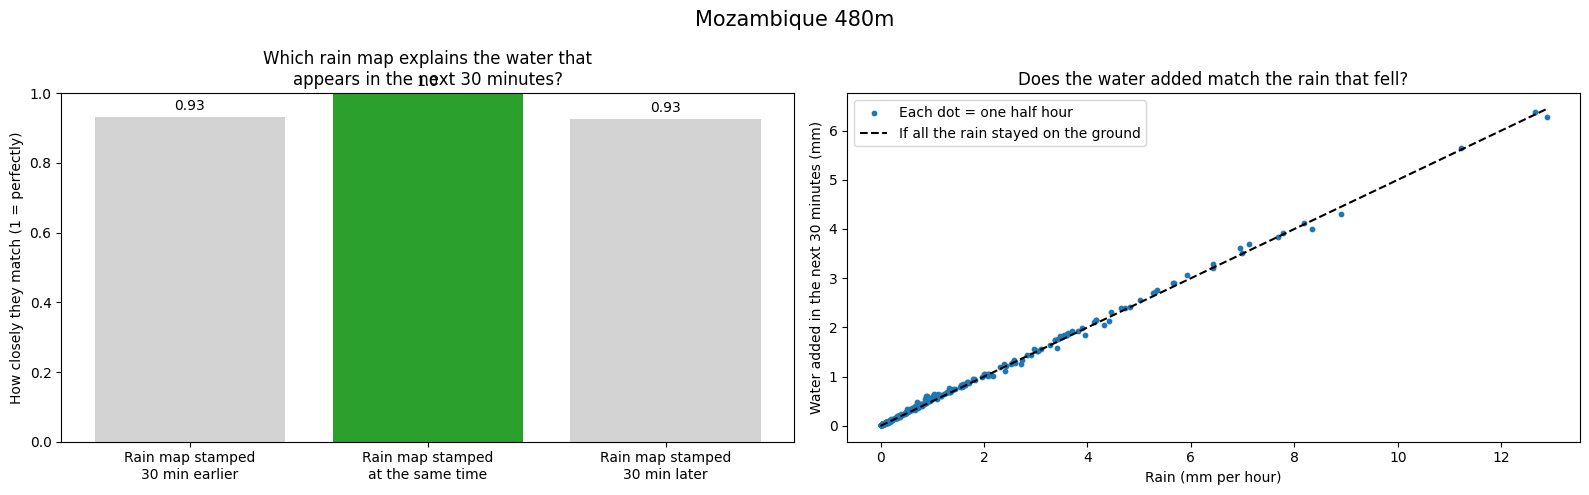

In [26]:
def match_strength(water_rise, rain, shift):
    # How closely the water rise follows the rain shifted by "shift" steps (1 = perfect match, 0 = no link)
    rise_values = []
    rain_values = []

    for step in range(len(water_rise)):
        rain_step = step + shift
        if 0 <= rain_step < len(rain) and not np.isnan(rain[rain_step]):
            rise_values.append(water_rise[step])
            rain_values.append(rain[rain_step])

    return np.corrcoef(rise_values, rain_values)[0, 1]


for dataset, m in measurements.items():
    # Water added to the map in each half hour, in millimetres
    water_rise = np.diff(m["average_depth"]) * 1000
    rain = m["average_rain"]

    # Match with the rain map stamped 30 minutes earlier, at the same time, and 30 minutes later
    strengths = [match_strength(water_rise, rain, -1),
                 match_strength(water_rise, rain, 0),
                 match_strength(water_rise, rain, 1)]

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(dataset, fontsize=15)

    # Left: which rain map explains the water rise best (the best one is green)
    labels = ["Rain map stamped\n30 min earlier", "Rain map stamped\nat the same time", "Rain map stamped\n30 min later"]
    colours = ["lightgrey", "lightgrey", "lightgrey"]
    colours[int(np.argmax(strengths))] = "tab:green"

    axes[0].bar(labels, strengths, color=colours)
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("How closely they match (1 = perfectly)")
    axes[0].set_title("Which rain map explains the water that\nappears in the next 30 minutes?")
    for position, value in enumerate(strengths):
        axes[0].text(position, value + 0.02, str(round(value, 2)), ha="center")

    # Right: rain against the water that appeared
    rain_same_time = rain[:len(water_rise)]
    usable = ~np.isnan(rain_same_time)
    axes[1].scatter(rain_same_time[usable], water_rise[usable], s=10, color="tab:blue", label="Each dot = one half hour")

    # Line for "all the rain stays on the ground": half an hour of rain = 0.5 x the hourly rate
    rain_range = np.linspace(0, np.nanmax(rain_same_time), 50)
    axes[1].plot(rain_range, 0.5 * rain_range, "k--", label="If all the rain stayed on the ground")

    axes[1].set_xlabel("Rain (mm per hour)")
    axes[1].set_ylabel("Water added in the next 30 minutes (mm)")
    axes[1].set_title("Does the water added match the rain that fell?")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## 7. Is the old "severe" label measuring the flood?

An earlier label called a 128 x 128 tile "severe" if any single square in it was 2 m deep or more.
Here we compare that with how much of each tile is really under more than 30 cm of water, at the wettest moment of each flood.

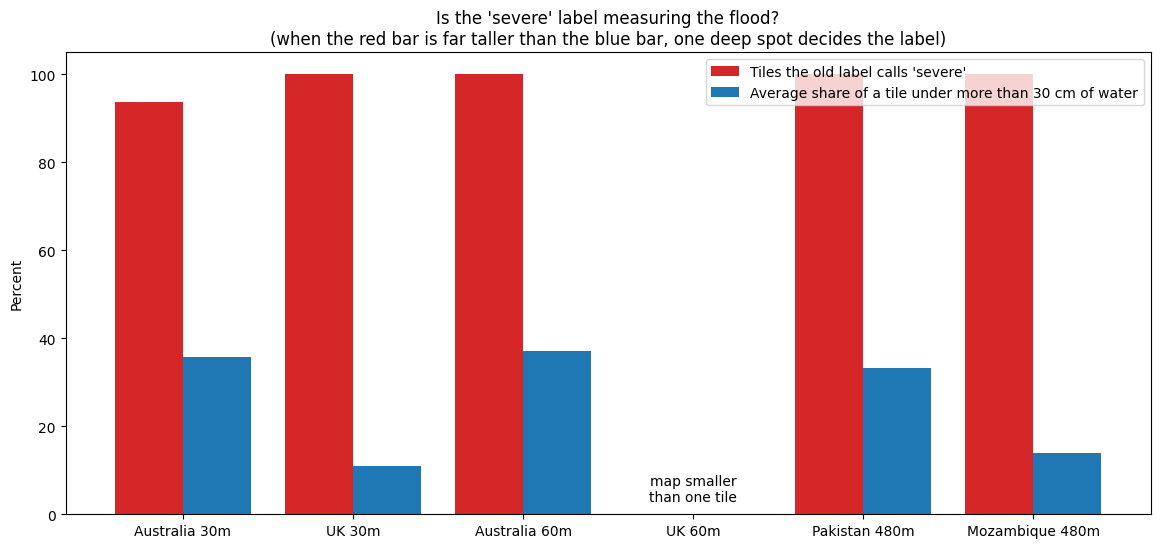

,Dataset,Tiles,Called severe (%),Actually flooded (%)
0,Australia 30m,64,93.75,35.733891
1,UK 30m,2,100.00,11.013794
2,Australia 60m,16,100.00,37.133026
3,UK 60m,0,0.00,0.000000
4,Pakistan 480m,18,100.00,33.198039
5,Mozambique 480m,1,100.00,13.867188


In [27]:
OLD_TILE_SIZE = 128

label_rows = []

for dataset, m in measurements.items():
    # The moment when the most area is under water
    wettest_step = int(np.argmax(m["wet_area"]))
    depth = read_map(get_depth_files(dataset)[wettest_step * DEPTH_MAPS_PER_RAIN_MAP])

    rows, columns = depth.shape

    tiles_called_severe = 0
    total_tiles = 0
    flooded_shares = []

    # Cut the map into 128 x 128 tiles
    for top in range(0, rows - OLD_TILE_SIZE + 1, OLD_TILE_SIZE):
        for left in range(0, columns - OLD_TILE_SIZE + 1, OLD_TILE_SIZE):
            tile = depth[top:top + OLD_TILE_SIZE, left:left + OLD_TILE_SIZE]
            total_tiles += 1

            # The old label: "severe" if any single square is 2 m deep or more
            if np.nanmax(tile) >= 2.0:
                tiles_called_severe += 1

            # Share of the tile really under more than 30 cm of water
            flooded_shares.append(np.nanmean(tile > 0.3))

    if total_tiles == 0:
        label_rows.append({"Dataset": dataset, "Tiles": 0, "Called severe (%)": 0, "Actually flooded (%)": 0})
    else:
        label_rows.append({"Dataset": dataset, "Tiles": total_tiles,
                           "Called severe (%)": 100 * tiles_called_severe / total_tiles,
                           "Actually flooded (%)": 100 * np.mean(flooded_shares)})

label_table = pd.DataFrame(label_rows)

# Bars side by side: what the label says against how much of each tile is really flooded
positions = np.arange(len(label_table))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(positions - bar_width / 2, label_table["Called severe (%)"], bar_width, color="tab:red",
       label="Tiles the old label calls 'severe'")
ax.bar(positions + bar_width / 2, label_table["Actually flooded (%)"], bar_width, color="tab:blue",
       label="Average share of a tile under more than 30 cm of water")

# Mark datasets whose map is smaller than one tile
for position, tiles in enumerate(label_table["Tiles"]):
    if tiles == 0:
        ax.text(position, 3, "map smaller\nthan one tile", ha="center")

ax.set_xticks(positions)
ax.set_xticklabels(label_table["Dataset"])
ax.set_ylabel("Percent")
ax.set_ylim(0, 105)
ax.set_title("Is the 'severe' label measuring the flood?\n(when the red bar is far taller than the blue bar, one deep spot decides the label)")
ax.legend()
plt.show()

display(label_table)

## 8. Summary

In [28]:
summary_rows = []

for dataset, m in measurements.items():
    wettest_step = int(np.argmax(m["wet_area"]))

    summary_rows.append({
        "Dataset": dataset,
        "Deepest water (m)": np.nanmax(m["deepest_point"]),
        "Most area under water (%)": 100 * m["wet_area"][wettest_step],
        "When (hours after start)": m["hours"][wettest_step],
        "Average depth then (cm)": 100 * m["average_depth"][wettest_step],
    })

display(pd.DataFrame(summary_rows))

,Dataset,Deepest water (m),Most area under water (%),When (hours after start),Average depth then (cm)
0,Australia 30m,19.209829,56.334115,171.5,30.829212
1,UK 30m,6.107450,49.332620,24.5,10.730105
2,Australia 60m,15.013915,67.851623,171.5,30.852280
3,UK 60m,4.883784,55.560326,24.5,10.783903
4,Pakistan 480m,26.671488,86.077937,132.5,34.532364
5,Mozambique 480m,12.412163,80.257222,54.0,15.381712
